## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


## <center>Extra: căutarea clasică a hiperparametrilor (GridSearchCV)</center>


**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. univ. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/05-clasificare/extra-05-tuning-clasic.ipynb)

In [1]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/05-clasificare
sys.path.insert(0, os.path.abspath("../.."))

> Material de referință din cursul 9: căutare exhaustivă cu `GridSearchCV` și validare încrucișată manuală. Rulează **zeci de minute** (mai ales în Colab). Pentru seminar folosiți varianta cu Optuna din modulul 6. Secțiunea despre kNN, arbori și random forest este inclusă pentru că exemplele de la final depind de ea.

# Compararea modelelor de clasificare

Pe date de antrenament putem folosi AUC. Dacă avem date de test, evaluăm metrici derivate din matricea de confuzie. 



Este uzual ca la compararea clasificatorilor să comparăm vizual matricile de confuzie. Pentru o alegere automată însă avem nevoie de un mod programatic de a determina cel mai bun dintre modele. În funcție de specificul problemei, se poate utiliza una din metricile uzuale:
- precision
- recall
- F1
- accuracy

## Exemplu - determinarea celui mai bun parametru pentru regularizarea regresiei logistice:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix
import sklearn.metrics as met


Data trecută am rămas la graficele cu AUC pentru diferite valori ale parametrului de regularizare **C**.

Modelul de regresie logistică dezbatut poate conține inclusiv un termen de interacțiune, așa cum se poate adăuga și la regresie:

In [3]:
df_heart = pd.read_csv('./date/Heart.csv',header = 0).iloc[:,1:]

df_heart

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
299,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
300,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes
301,57,0,nontypical,130,236,0,2,174,0,0.0,2,1.0,normal,Yes


In [4]:
# introducem un termen de interactiune (ceea ce nu am incercat la regresie liniara...)

df_heart['Interaction'] = df_heart.MaxHR * df_heart.Sex 

In [5]:
[2**i for i in range(-3,8)]

[0.125, 0.25, 0.5, 1, 2, 4, 8, 16, 32, 64, 128]

In [6]:
beta1_l1 = []
beta1_l2 = []
Cs = []
AUC1s = []
AUC2s =[]
data_x = df_heart[['MaxHR','Sex','Interaction']]
data_y = df_heart['AHD']

result = []
# incercam diferite valori pentru C si observam efectul asupra valorilor ACU rezultate

for C in [2**i for i in range(-4,8)]:
    #C = 1/i  #2**(10*i)
    
    logitm_l1 = LogisticRegression(C = C, l1_ratio = 1, solver='liblinear',max_iter=2000)
    logitm_l1.fit (data_x, data_y)
    
    logitm_l2 = LogisticRegression(C = C, l1_ratio = 0, solver='lbfgs')
    logitm_l2.fit (data_x, data_y)
    
    beta1_l1.append(logitm_l1.coef_[0])
    beta1_l2.append(logitm_l2.coef_[0])
    
    Cs.append(C)
    
    
    y_hat1 = logitm_l1.predict_proba(df_heart[['MaxHR','Sex','Interaction']])[:,1]

    AUC1s.append(met.roc_auc_score(df_heart['AHD'], y_hat1))
    y_hat2 = logitm_l2.predict_proba(df_heart[['MaxHR','Sex','Interaction']])[:,1]

    AUC2s.append(met.roc_auc_score(df_heart['AHD'], y_hat2))
    
    result.append(
    {
        'C_param':C,
        'AUC_l1':met.roc_auc_score(df_heart['AHD'], y_hat1),
        'AUC_l2':met.roc_auc_score(df_heart['AHD'], y_hat2),
        'accuracy_l1': met.accuracy_score(df_heart['AHD'], logitm_l1.predict(df_heart[['MaxHR','Sex','Interaction']])),
        'accuracy_l2': met.accuracy_score(df_heart['AHD'], logitm_l2.predict(df_heart[['MaxHR','Sex','Interaction']])),
    }
    )

In [7]:
pd.DataFrame(result).sort_values(by = 'AUC_l2', ascending = False)#.C_param.values[0]

,C_param,AUC_l1,AUC_l2,accuracy_l1,accuracy_l2
10,64.0000,0.789261,0.788998,0.709571,0.709571
11,128.0000,0.789261,0.788954,0.709571,0.709571
9,32.0000,0.789261,0.788296,0.709571,0.709571
8,16.0000,0.789305,0.787814,0.709571,0.702970
7,8.0000,0.789042,0.786103,0.709571,0.702970
6,4.0000,0.788647,0.784611,0.709571,0.689769
5,2.0000,0.788603,0.783251,0.709571,0.693069
4,1.0000,0.786849,0.781628,0.709571,0.689769
3,0.5000,0.783866,0.780225,0.709571,0.689769
2,0.2500,0.780532,0.780049,0.709571,0.689769


In [8]:
import plotly.graph_objects as go

df_to_plot = pd.DataFrame(result).sort_values(by = 'C_param')
# Create traces
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_to_plot.C_param, 
                         y=df_to_plot.AUC_l1,
                    mode='lines+markers',
                    name='l1-normalization'))
fig.add_trace(go.Scatter(x=df_to_plot.C_param, 
                         y=df_to_plot.AUC_l2,
                    mode='lines+markers',
                    name='l2-normalization'))


fig.update_layout(xaxis_title ='C-param',
yaxis_title = 'AUC',
                 title = 'AUC pentru model antrenat pe toate datele')
fig.show()

In [9]:
import plotly.graph_objects as go

df_to_plot = pd.DataFrame(result).sort_values(by = 'C_param')
# Create traces
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_to_plot.C_param, 
                         y=df_to_plot.accuracy_l1,
                    mode='lines+markers',
                    name='l1-normalization'))
fig.add_trace(go.Scatter(x=df_to_plot.C_param, 
                         y=df_to_plot.accuracy_l2,
                    mode='lines+markers',
                    name='l2-normalization'))

fig.update_layout(xaxis_title ='C-param',
yaxis_title = 'Acuratețe',
                  title = 'Acuratețe pentru model antrenat pe toate datele')
fig.show()

**CARE ESTE PROBLEMA CU ACEST MODEL?** (Indiciu: pe ce date a fost antrenat? Pe ce date a fost evaluat?)

Mai util ar fi să ajungem la o concluzie programatic, automat, despre valoarea optimă pentru **C**.

Pregătim lista de parametrii pe care vrem să îi încercăm. Cheile au un format specific:

- cheile sunt numele parametrilor așa cum apar în documentație; valorile pentru aceste chei sunt liste cu valori posibile

Parametrii de modelare:

In [10]:
param_grid = [
     { 
         'l1_ratio' : [1, 0],               # tipul de regularizare: 1 = L1 (Lasso), 0 = L2 (Ridge)
         'C' : [2**i for i in range(-4,10)], # parametrul C al regularizarii
         'solver' : ['liblinear']           # tipul de algoritm folosit in aproximarea coeficientilor modelului
     }
]

In [11]:
pd.DataFrame( [
     { 
         'l1_ratio' :p,         # tipul de regularizare: 1 = L1 (Lasso), 0 = L2 (Ridge)
         'C' : C, # parametrul C al regularizarii
         'solver' :  s          # tipul de algoritm folosit in aproximarea coeficientilor modelului
     }
    
    for p in [1, 0]
    for C in [2**i for i in range(-4,10)]
    for s in ['liblinear']
])

,l1_ratio,C,solver
0,1,0.0625,liblinear
1,1,0.1250,liblinear
2,1,0.2500,liblinear
3,1,0.5000,liblinear
4,1,1.0000,liblinear
5,1,2.0000,liblinear
6,1,4.0000,liblinear
7,1,8.0000,liblinear
8,1,16.0000,liblinear
9,1,32.0000,liblinear


In [12]:
df_heart['AHD'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Atributele și variabila țintă:

In [13]:
df_heart['AHD1'] = df_heart['AHD'].apply(lambda x:
                                       1 if x == 'Yes' else 0)

X = df_heart[['MaxHR','Sex','Interaction']] # covariate/atribute predictive/features/ cele cu care ne ajutam in prognoza
y = df_heart['AHD1'] # variabila pe care o prezicem

In [14]:
df_heart.groupby(['AHD1']).MaxHR.count()/len(df_heart)

AHD1
0    0.541254
1    0.458746
Name: MaxHR, dtype: float64

## Efectul  stratificarii

In [15]:
#fara startificare
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    # random_state = 777
                                                   )

In [16]:
print(
    f'''Proportie clasa 1 in (y_train, y_test):({100*len([t for t in y_train if t==1])/len(y_train):0.2f}%, {100*len([t for t in y_test if t==1])/len(y_test):0.2f}%)
''')


Proportie clasa 1 in (y_train, y_test):(48.35%, 36.07%)



In [17]:
# cu stratificare
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y,
                                                   # random_state = 777
                                                   )

In [18]:
print(
    f'''Proportie clasa 1 dupa stratificare in (y_train, y_test):({100*len([t for t in y_train if t==1])/len(y_train):0.2f}%, {100*len([t for t in y_test if t==1])/len(y_test):0.2f}%)
''')


Proportie clasa 1 dupa stratificare in (y_train, y_test):(45.87%, 45.90%)



In [19]:
#Antrenarea si testarea
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y, random_state = 777)

# setup antrenare cu validare incurcisata
CV= GridSearchCV(LogisticRegression(), # modelul de clasificare
                 param_grid, # parametrii
                 cv= 10, # numarul de submultimi pentru validare incrucisata pe date de antrenament
                 scoring='accuracy', # precision ,f1, auc
                 verbose=1, 
                 n_jobs = -1 #toate procesoarele
                )

# antrenare cu validare incrucisata
CV.fit(X_train, y_train)   

print('Atribute:', X.columns)
print('Cel mai bun scor de antrenament: ', CV.best_score_)
print('Parametrii aferenți:', CV.best_params_)

Fitting 10 folds for each of 28 candidates, totalling 280 fits


Atribute: Index(['MaxHR', 'Sex', 'Interaction'], dtype='str')
Cel mai bun scor de antrenament:  0.7194999999999999
Parametrii aferenți: {'C': 0.25, 'l1_ratio': 0, 'solver': 'liblinear'}


In [20]:
model_final = LogisticRegression( C =  0.25, l1_ratio = 0, solver= 'liblinear')
model_final.fit(X_train,y_train)
y_train_hat = model_final.predict(X_train)
print('Metrici finale pe test:')
print('Matrice confuzie pe X_train (potrivirea):\n')
disp= met.ConfusionMatrixDisplay(met.confusion_matrix(y_true = y_train,y_pred = y_train_hat))
disp.plot()
plt.show()
met.precision_recall_fscore_support (y_train, y_train_hat)

met.classification_report (y_train, y_train_hat)
y_test_hat = model_final.predict(X_test)
print('Metrici finale pe test:')

print('Matrice confuzie pe X_test (evaluarea):\n')
disp= met.ConfusionMatrixDisplay(met.confusion_matrix(y_test, y_test_hat))
disp.plot()
plt.show()
met.classification_report (y_test,y_test_hat)


Metrici finale pe test:
Matrice confuzie pe X_train (potrivirea):

Metrici finale pe test:
Matrice confuzie pe X_test (evaluarea):



'              precision    recall  f1-score   support\n\n           0       0.67      0.79      0.72        33\n           1       0.68      0.54      0.60        28\n\n    accuracy                           0.67        61\n   macro avg       0.67      0.66      0.66        61\nweighted avg       0.67      0.67      0.67        61\n'

In [21]:
X_test

,MaxHR,Sex,Interaction
122,143,1,143
117,182,0,0
104,139,1,139
199,125,1,125
151,122,0,0
...,...,...,...
131,154,1,154
36,120,1,120
130,147,1,147
262,171,0,0


In [22]:
y_test

122    0
117    0
104    1
199    1
151    0
      ..
131    0
36     1
130    0
262    0
89     0
Name: AHD1, Length: 61, dtype: int64

In [23]:
met.precision_score (y_test,y_test_hat)

0.6818181818181818

Acum să încercăm un model cu toți parametrii care sunt numerici.

O să și sparg datele în mod repetat, fără folosirea random_state.

In [24]:
model_final.predict_proba(X_test)

array([[0.45144899, 0.54855101],
       [0.82745543, 0.17254457],
       [0.43837171, 0.56162829],
       [0.39338251, 0.60661749],
       [0.66721812, 0.33278188],
       [0.81021744, 0.18978256],
       [0.61374405, 0.38625595],
       [0.32643159, 0.67356841],
       [0.80797246, 0.19202754],
       [0.77441418, 0.22558582],
       [0.54056793, 0.45943207],
       [0.47448558, 0.52551442],
       [0.5504145 , 0.4495855 ],
       [0.50094096, 0.49905904],
       [0.77694318, 0.22305682],
       [0.46459367, 0.53540633],
       [0.45472954, 0.54527046],
       [0.5504145 , 0.4495855 ],
       [0.41570151, 0.58429849],
       [0.78440844, 0.21559156],
       [0.35013203, 0.64986797],
       [0.5504145 , 0.4495855 ],
       [0.50425055, 0.49574945],
       [0.64091869, 0.35908131],
       [0.56673431, 0.43326569],
       [0.52739107, 0.47260893],
       [0.55368831, 0.44631169],
       [0.80570729, 0.19429271],
       [0.44490081, 0.55509919],
       [0.49432181, 0.50567819],
       [0.

In [25]:
X = df_heart[['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR',
       'ExAng', 'Oldpeak', 'Slope']]
y = df_heart['AHD']

In [26]:
#Antrenarea si testarea
overall = []
for i in range(10):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y) # 

    # setup antrenare cu validare incurcisata
    CV= GridSearchCV(LogisticRegression(), # modelul de clasificare
                     param_grid, # parametrii
                     cv= 10, # numarul de submultimi pentru validare incrucisata pe date de antrenament
                     scoring='accuracy', 
                     verbose=1, 
                     n_jobs = -1 #toate procesoarele
                    )

    # antrenare cu validare incrucisata
    CV.fit(X_train, y_train)   

    print('Iterația: ', i)
    print('Cel mai bun scor de antrenament: ', CV.best_score_)
    print('Parametrii aferenți:', CV.best_params_)
    
    model_final = LogisticRegression( C =  CV.best_params_['C'], 
                                     l1_ratio = CV.best_params_['l1_ratio'], 
                                     solver= CV.best_params_['solver'],
                                     max_iter=2000)
    model_final.fit(X_train,y_train)
    y_train_hat = model_final.predict(X_train)

    #print('Matrice confuzie pe X_train (potrivirea):\n')
    #disp= met.ConfusionMatrixDisplay(met.roc_auc_score(y_train, y_train_hat))
    #print('roc_auc_score:', met.roc_auc_score(y_train, y_train_hat))
    met.precision_recall_fscore_support (y_train, y_train_hat)
    y_test_hat = model_final.predict(X_test)


    #print('Matrice confuzie pe X_test (evaluarea):\n')
    #disp= met.ConfusionMatrixDisplay(met.confusion_matrix(y_test, y_test_hat))
    #disp.plot()
    #  plt.show()
    met.precision_recall_fscore_support (y_test,y_test_hat)
    
    overall.append(
    {
        'i':i,
        'parametrii': CV.best_params_,
         'C' : CV.best_params_['C'], 
         'l1_ratio' : CV.best_params_['l1_ratio'], 
         'solver': CV.best_params_['solver'],
        'acuratețe test':met.accuracy_score(y_test,y_test_hat)
    })
    #print('===============================================================================')
    
pd.DataFrame(overall)  

Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  0
Cel mai bun scor de antrenament:  0.7976666666666666
Parametrii aferenți: {'C': 128, 'l1_ratio': 1, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  1
Cel mai bun scor de antrenament:  0.7636666666666667
Parametrii aferenți: {'C': 0.25, 'l1_ratio': 0, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  2
Cel mai bun scor de antrenament:  0.781
Parametrii aferenți: {'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  3
Cel mai bun scor de antrenament:  0.7726666666666667
Parametrii aferenți: {'C': 0.0625, 'l1_ratio': 0, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


...

Iterația:  6
Cel mai bun scor de antrenament:  0.8058333333333334
Parametrii aferenți: {'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  7
Cel mai bun scor de antrenament:  0.7641666666666668
Parametrii aferenți: {'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  8
Cel mai bun scor de antrenament:  0.7761666666666667
Parametrii aferenți: {'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}
Fitting 10 folds for each of 28 candidates, totalling 280 fits


Iterația:  9
Cel mai bun scor de antrenament:  0.7763333333333333
Parametrii aferenți: {'C': 0.125, 'l1_ratio': 0, 'solver': 'liblinear'}


,i,parametrii,C,l1_ratio,solver,acuratețe test
0,0,"{'C': 128, 'l1_ratio': 1, 'solver': 'liblinear'}",128.0000,1,liblinear,0.754098
1,1,"{'C': 0.25, 'l1_ratio': 0, 'solver': 'liblinear'}",0.2500,0,liblinear,0.852459
2,2,"{'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}",0.5000,0,liblinear,0.770492
3,3,"{'C': 0.0625, 'l1_ratio': 0, 'solver': 'liblin...",0.0625,0,liblinear,0.754098
4,4,"{'C': 0.125, 'l1_ratio': 0, 'solver': 'libline...",0.1250,0,liblinear,0.786885
5,5,"{'C': 2, 'l1_ratio': 1, 'solver': 'liblinear'}",2.0000,1,liblinear,0.819672
6,6,"{'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}",0.5000,1,liblinear,0.721311
7,7,"{'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}",0.5000,0,liblinear,0.819672
8,8,"{'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}",0.5000,1,liblinear,0.819672
9,9,"{'C': 0.125, 'l1_ratio': 0, 'solver': 'libline...",0.1250,0,liblinear,0.770492


In [27]:
pd.DataFrame(overall).sort_values(by = 'acuratețe test',ascending = False)

,i,parametrii,C,l1_ratio,solver,acuratețe test
1,1,"{'C': 0.25, 'l1_ratio': 0, 'solver': 'liblinear'}",0.2500,0,liblinear,0.852459
5,5,"{'C': 2, 'l1_ratio': 1, 'solver': 'liblinear'}",2.0000,1,liblinear,0.819672
8,8,"{'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}",0.5000,1,liblinear,0.819672
7,7,"{'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}",0.5000,0,liblinear,0.819672
4,4,"{'C': 0.125, 'l1_ratio': 0, 'solver': 'libline...",0.1250,0,liblinear,0.786885
9,9,"{'C': 0.125, 'l1_ratio': 0, 'solver': 'libline...",0.1250,0,liblinear,0.770492
2,2,"{'C': 0.5, 'l1_ratio': 0, 'solver': 'liblinear'}",0.5000,0,liblinear,0.770492
0,0,"{'C': 128, 'l1_ratio': 1, 'solver': 'liblinear'}",128.0000,1,liblinear,0.754098
3,3,"{'C': 0.0625, 'l1_ratio': 0, 'solver': 'liblin...",0.0625,0,liblinear,0.754098
6,6,"{'C': 0.5, 'l1_ratio': 1, 'solver': 'liblinear'}",0.5000,1,liblinear,0.721311


Observăm o creștere în acuratețe de la 73% la 87% deci aproape 14 puncte procentuale, adica o creștere de aproape 20% (10% din 73 este 7,3).

A meritat deci efortul includerii tuturor atributelor. Și C are o alta valoare.

# Lucrul cu date de antrenament 

`Rețineți` Atunci când în datele observate proporția claselor diferă semnificativ ca ordin de mărime - o clasă reprezentând mai puțin de 10% din date (uneori chiar mult mai puțin, în cazul problemelor în care se caută valori extreme), spunem că suntem în prezența unor clase nebalansate. Există tehnici de balansare, cod open source Python sub forma unor pachete de funcții și clase - despre modulul `imblearn` am discutat deja. <b>Dacă aveți de a face cu clase nebalansate în cadrul proiectelor, vă rog să mă contactați ca să vă îndrum.</b>


## Eșantioare stratificată



În clasificare antrenamentul depinde de ponderea claselor în setul de date. Pentru clasificare binară o pondere echilibrată, balansată, a celor două clase în variabila țintă e rar întâlnită. Adesea o clasă domină.

Vom discuta despre balansare în semestrul II. Presupunem că raportul de mărime al claselor este similar (de exemplu un raport procentual 40-60, 35-75  chiar și pâna la 20-80 e înca ok dacă setul de date are suficiente înregistrări). În aceste cazuri nu mai este necesară balansarea.

Pentru a surprinde proporția reală din clase echilibate rezonabil  setul de antrenament trebuie construit în așa fel încât să respecte această proporție. 

Să presupunem că dorim să păstrăm 30% din date pentru test și antrenăm pe 70% din date. 

Să mai presupunem că ponderea în setul inițial este 60% clasa 1, 40% clasa 0. 

Pentru a regăsi această proporție în setul de antrenament ar trebuie să separam setul de date în cel al clasei 1, să alegem aleator 70% pentru antrenament, 30% pentru test. Apoi facem același lucru cu clasa 0 și reunim seturile de antrenament într-unul în care avem 70% din date iar ponderea e 60%  clasa 1 și 40% clasa 0. Aceasta este o eșantionare stratificată.

Python ofera mai multe soluții care să realizeze cele de mai sus în mod automat într-un pachet de funcții scikit-learn:
`StratifiedShuffleSplit` este una din aceste metode.

Soluția de mai sus face chiar mai multe decât am cerut. O vom folosi cu  `n_splits = 1` mai jos, unde `n_splits` este numărul de submulțimi pe care le putem crea pentru validare încrucișată - în cazul nostru ne rezumăm la o singură pereche train/test aleasă aleator.

### Exemplu
În exemplul de mai jos se studiază în ce măsură se poate determina predispoziția pentru diabet. Variabila țintă este coloana `label`. 

In [28]:
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit

col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']

# incarcare set de date
pima = pd.read_csv("./date/pima-indians-diabetes.csv", header=0, names=col_names)

# instantiere clasa de esantionare stratificata
train_test_selector = StratifiedShuffleSplit(n_splits =1, test_size = 0.3, random_state = 77)

# bucla prin valorile variabilei target (in cazul nostru binare) pentru a construi seturile de train, test
for train_idx, test_idx in train_test_selector.split(pima,pima['label']):
    train_set = pima.loc[train_idx]
    test_set = pima.loc[test_idx]

print(train_set.shape[0] + test_set.shape[0], pima.shape[0])
display(train_set.head(5))
print('Proportie clase in setul initial: clasa 0 -', pima[pima.label ==0].shape[0]/pima.shape[0] )
print('Proportie clase in setul de antrenament: clasa 0 -', train_set[train_set.label ==0].shape[0]/train_set.shape[0] )
print('Proportie clase in setul de testare: clasa 0 - ', test_set[test_set.label ==0].shape[0]/test_set.shape[0] )

768 768


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
714,3,102,74,0,0,29.5,0.121,32,0
328,2,102,86,36,120,45.5,0.127,23,1
530,2,122,60,18,106,29.8,0.717,22,0
4,0,137,40,35,168,43.1,2.288,33,1
389,3,100,68,23,81,31.6,0.949,28,0


Proportie clase in setul initial: clasa 0 - 0.6510416666666666
Proportie clase in setul de antrenament: clasa 0 - 0.6517690875232774
Proportie clase in setul de testare: clasa 0 -  0.6493506493506493


# Clasificare cu scikit learn

Scikit-Learn oferă acces facil la numeroși algoritmi de clasificare diferiți. Printre acești clasificatori se numără:

- K-Nearest Neighbors (cei mai apropiati K vecini)
- Decision Tree Classifiers/Random Forests `RF`(arbori de decizie/paduri aleatoare)
- Boosting Trees (xgboost)
- Support Vector Machines `SVM`(masini cu suport vectorial)
Vom discuta mai in detaliu 2 clasificatori: `SVM` si `RF`.
    

## K-Nearest Neighbors

KNN operează verificând distanța de la un exemplu de test până la valorile cunoscute ale unui exemplu de instruire. Grupul de puncte / clasă de date care ar oferi cea mai mică distanță între punctele de antrenament și punctul de testare este clasa selectată (mai precis clasa cu cele mai multe puncte apropiate de punctul de test pentru care se doreste clasificarea).

Parametru:

> $k$ - numarul de vecini considerati pentru a masura distantele si a obtine votul majoritar

De exemplu pentru $k=3$ se vor considera 3 vecini in setul de antrenament. Pentru clasificare binara asta inseamna ca cel putin doi dintre cei 3 cei mai apropiati vecini vor fi intr-o clasa astfel ca votul majoritar va fi obtinut.

> De retinut: 'modelul' in acest caz este intreg setul de date pentru ca in prognoza punctele noi vor fi comparate cu intreg setul de date pentru a gasi cei mai apropiati $k$ vecini. Asta inseamna ca modelul nu e foarte eficient - de fiecare data va calcula toate distantele si va ordona intregul set de distante pentru a gasi cei mai apropiati $k$ vecini.

În cele ce urmează  prezentăm modul general prin care testăm dacă un model produce rezultate.

Procedură:
- validare încrucișată. De multe ori este implementată alături de model. Acestea însă se pot aplica doar în cazul în care nu aveți operațiuni intermediare asupra datelor de antrenament. 

### ATENȚIE MARE: de exemplu dacă normalizați datele cu standard scaler
La validare încrucișată, la spargerea setului de date în 10 bucăți aleatoriu, se scoate pe rând una din submulțimi pentru evaluare. Pe cele 9 rămase se pregătește antrenamentul: se determină media si deviația standard, se normalizează datele - de exemplu pentru atributul $X_i$ din coloana $i$:

$$
\begin{align} 
\mu^{train}_i = \frac{1}{N-1}\sum_kX^{train}_{i,k}, \\
\sigma^{train}_i =\sqrt{\frac{\sum_k(X^{train}_{i,k}-\mu_i)^2}{N-1}}, \\
\widetilde{X^{train}_{i}}=\frac{(X^{train}_{i}-\mu^{train}_i)}{\sigma^{train}_i} 
\end{align}
$$

și datele normalizate $\widetilde{X^{train}_i}$ sunt folosite in modelare. Apoi datele de evaluare vor fi normalizate cu <b>aceeiași medie și deviație standard</b> $\mu^{train}_i, \sigma^{train}_i$, adică:
$$
\begin{align} 
\widetilde{X^{eval}_{i}}=\frac{(X^{eval}_{i}-\mu^{train}_i)}{\sigma^{train}_i}.
\end{align}
$$

La fel se întâmplă când aveți atribute derivate la nivel de date de antrenament - frecvențe, etc. De aceea e bine să folosiți cu grijă validările încrucișate oferite. Mai bine scrieți codul care vă ajută după cum am făcut în exemplul de mai jos.


## Exemplu clasificare kNN

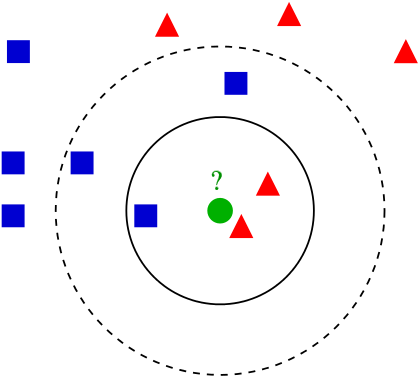



Credit <a href="https://commons.wikimedia.org/w/index.php?curid=2170282" class="dc by ii ij ik il" target="_blank" rel="noopener nofollow">Antti Ajanki AnAj</a>


In [29]:
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
# incarcare set date
pima = pd.read_csv("./date/pima-indians-diabetes.csv", header=0, names=col_names)

In [30]:
pima.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [31]:
for c in pima.columns:
    if c =='label': continue
    print(c)
    display(pima.groupby('label',as_index = False)[c].agg(['min','max','mean','median']))

pregnant


,label,min,max,mean,median
0,0,0,13,3.298000,2.0
1,1,0,17,4.865672,4.0


glucose


,label,min,max,mean,median
0,0,0,197,109.980000,107.0
1,1,0,199,141.257463,140.0


bp


...

,label,min,max,mean,median
0,0,0.0,57.3,30.304200,30.05
1,1,0.0,67.1,35.142537,34.25


pedigree


,label,min,max,mean,median
0,0,0.078,2.329,0.429734,0.336
1,1,0.088,2.420,0.550500,0.449


age


,label,min,max,mean,median
0,0,21,81,31.190000,27.0
1,1,21,70,37.067164,36.0


In [32]:
pima.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pregnant  768 non-null    int64  
 1   glucose   768 non-null    int64  
 2   bp        768 non-null    int64  
 3   skin      768 non-null    int64  
 4   insulin   768 non-null    int64  
 5   bmi       768 non-null    float64
 6   pedigree  768 non-null    float64
 7   age       768 non-null    int64  
 8   label     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [33]:
# from sklearn.model_selection import StratifiedKFold
# StratifiedKFold(n_splits=2, random_state=None, shuffle=False)

Toate variabilele sunt numerice, nu avem null-uri, putem modela.

In [34]:
from numpy import mean
from numpy import std
from sklearn.metrics import confusion_matrix,precision_recall_fscore_support,classification_report,auc


from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

import sklearn.metrics as met

# instantiere clasa de esantionare stratificata - alege spargerea 10 pentru validare încrucișată
train_test_selector = StratifiedShuffleSplit(n_splits =10, test_size = 0.3)#, random_state = 77)
columns_for_training = [c for c in col_names if c!='label']

# pentru rezutate
res_train = []
res_test = []
# enumerare validări încrucișate
i = 1
for train_idx, test_idx in train_test_selector.split(pima,pima['label']):
    
    train_set = pima.loc[train_idx]
    test_set = pima.loc[test_idx]
    
    print(i, train_set.shape[0] + test_set.shape[0])
    
    # preparere variabila răspuns
    ytrain, ytest = train_set['label'], test_set['label']
    
    # preparare predictori
    Xtrain = train_set[columns_for_training].to_numpy()  
    Xtest = test_set[columns_for_training].to_numpy()
    
    # buclă după număr vecini
    for k in range(2,20):
        kNN_cslf = KNeighborsClassifier(n_neighbors=k)
        kNN_cslf.fit(Xtrain, ytrain)

        # fitting error
        y_fit_reg = kNN_cslf.predict(Xtrain)
        a=met.roc_auc_score(ytrain, y_fit_reg)
        res_train.append(({"cv_step":i,"k":k, "AUC":a}))
        
        # error on test - unseen data
        y_pred_reg = kNN_cslf.predict(Xtest)

        b=confusion_matrix( ytest,y_pred_reg) # pe linii adevarul, pe coloane prognoza!!
        c = met.accuracy_score( ytest,y_pred_reg)
        res_test.append({"cv_step":i,"k":k, "confusion matrix":b,"accuracy":c})
        print(classification_report( ytest,y_pred_reg))
    
    i = i + 1
    
display(pd.DataFrame(res_train))
display(pd.DataFrame(res_test))

1 768
              precision    recall  f1-score   support

           0       0.72      0.91      0.80       150
           1       0.66      0.33      0.44        81

    accuracy                           0.71       231
   macro avg       0.69      0.62      0.62       231
weighted avg       0.70      0.71      0.67       231

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       150
           1       0.60      0.49      0.54        81

    accuracy                           0.71       231
   macro avg       0.67      0.66      0.66       231
weighted avg       0.70      0.71      0.70       231

              precision    recall  f1-score   support

           0       0.73      0.89      0.80       150
           1       0.65      0.40      0.49        81

    accuracy                           0.71       231
   macro avg       0.69      0.64      0.65       231
weighted avg       0.70      0.71      0.69       231

             

              precision    recall  f1-score   support

           0       0.77      0.88      0.82       150
           1       0.69      0.51      0.59        81

    accuracy                           0.75       231
   macro avg       0.73      0.69      0.70       231
weighted avg       0.74      0.75      0.74       231

              precision    recall  f1-score   support

           0       0.73      0.93      0.82       150
           1       0.75      0.37      0.50        81

    accuracy                           0.74       231
   macro avg       0.74      0.65      0.66       231
weighted avg       0.74      0.74      0.71       231

              precision    recall  f1-score   support

           0       0.76      0.87      0.81       150
           1       0.67      0.51      0.58        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.69       231
weighted avg       0.73      0.74      0.73       231

              preci

              precision    recall  f1-score   support

           0       0.73      0.94      0.82       150
           1       0.76      0.36      0.49        81

    accuracy                           0.74       231
   macro avg       0.75      0.65      0.65       231
weighted avg       0.74      0.74      0.70       231

              precision    recall  f1-score   support

           0       0.76      0.92      0.83       150
           1       0.76      0.46      0.57        81

    accuracy                           0.76       231
   macro avg       0.76      0.69      0.70       231
weighted avg       0.76      0.76      0.74       231

              precision    recall  f1-score   support

           0       0.73      0.94      0.82       150
           1       0.77      0.37      0.50        81

    accuracy                           0.74       231
   macro avg       0.75      0.66      0.66       231
weighted avg       0.75      0.74      0.71       231

              preci

              precision    recall  f1-score   support

           0       0.72      0.94      0.82       150
           1       0.74      0.32      0.45        81

    accuracy                           0.72       231
   macro avg       0.73      0.63      0.63       231
weighted avg       0.73      0.72      0.69       231

              precision    recall  f1-score   support

           0       0.73      0.81      0.77       150
           1       0.56      0.46      0.50        81

    accuracy                           0.68       231
   macro avg       0.65      0.63      0.64       231
weighted avg       0.67      0.68      0.68       231

              precision    recall  f1-score   support

           0       0.72      0.90      0.80       150
           1       0.65      0.35      0.45        81

    accuracy                           0.71       231
   macro avg       0.68      0.62      0.63       231
weighted avg       0.69      0.71      0.68       231

              preci

              precision    recall  f1-score   support

           0       0.75      0.88      0.81       150
           1       0.67      0.44      0.53        81

    accuracy                           0.73       231
   macro avg       0.71      0.66      0.67       231
weighted avg       0.72      0.73      0.71       231

              precision    recall  f1-score   support

           0       0.75      0.85      0.80       150
           1       0.64      0.48      0.55        81

    accuracy                           0.72       231
   macro avg       0.70      0.67      0.67       231
weighted avg       0.71      0.72      0.71       231

              precision    recall  f1-score   support

           0       0.76      0.89      0.82       150
           1       0.70      0.47      0.56        81

    accuracy                           0.74       231
   macro avg       0.73      0.68      0.69       231
weighted avg       0.74      0.74      0.73       231

              preci

...

              precision    recall  f1-score   support

           0       0.75      0.92      0.83       150
           1       0.74      0.43      0.55        81

    accuracy                           0.75       231
   macro avg       0.75      0.68      0.69       231
weighted avg       0.75      0.75      0.73       231

              precision    recall  f1-score   support

           0       0.77      0.91      0.83       150
           1       0.75      0.51      0.60        81

    accuracy                           0.77       231
   macro avg       0.76      0.71      0.72       231
weighted avg       0.76      0.77      0.75       231

8 768
              precision    recall  f1-score   support

           0       0.72      0.95      0.82       150
           1       0.77      0.33      0.47        81

    accuracy                           0.73       231
   macro avg       0.75      0.64      0.64       231
weighted avg       0.74      0.73      0.70       231

             

              precision    recall  f1-score   support

           0       0.78      0.83      0.80       150
           1       0.64      0.56      0.60        81

    accuracy                           0.74       231
   macro avg       0.71      0.69      0.70       231
weighted avg       0.73      0.74      0.73       231

              precision    recall  f1-score   support

           0       0.77      0.91      0.83       150
           1       0.74      0.49      0.59        81

    accuracy                           0.76       231
   macro avg       0.75      0.70      0.71       231
weighted avg       0.76      0.76      0.75       231

              precision    recall  f1-score   support

           0       0.77      0.86      0.81       150
           1       0.67      0.52      0.58        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.70       231
weighted avg       0.73      0.74      0.73       231

              preci

              precision    recall  f1-score   support

           0       0.76      0.91      0.83       150
           1       0.75      0.47      0.58        81

    accuracy                           0.76       231
   macro avg       0.75      0.69      0.70       231
weighted avg       0.76      0.76      0.74       231

              precision    recall  f1-score   support

           0       0.79      0.89      0.83       150
           1       0.73      0.56      0.63        81

    accuracy                           0.77       231
   macro avg       0.76      0.72      0.73       231
weighted avg       0.77      0.77      0.76       231

              precision    recall  f1-score   support

           0       0.77      0.91      0.83       150
           1       0.75      0.51      0.60        81

    accuracy                           0.77       231
   macro avg       0.76      0.71      0.72       231
weighted avg       0.76      0.77      0.75       231

              preci

,cv_step,k,AUC
0,1,2,0.770053
1,1,3,0.844515
2,1,4,0.754156
3,1,5,0.772101
4,1,6,0.725806
...,...,...,...
175,10,15,0.737853
176,10,16,0.729137
177,10,17,0.740710
178,10,18,0.722544


,cv_step,k,confusion matrix,accuracy
0,1,2,"[[136, 14], [54, 27]]",0.705628
1,1,3,"[[123, 27], [41, 40]]",0.705628
2,1,4,"[[133, 17], [49, 32]]",0.714286
3,1,5,"[[131, 19], [40, 41]]",0.744589
4,1,6,"[[133, 17], [47, 34]]",0.722944
...,...,...,...,...
175,10,15,"[[123, 27], [42, 39]]",0.701299
176,10,16,"[[127, 23], [45, 36]]",0.705628
177,10,17,"[[125, 25], [40, 41]]",0.718615
178,10,18,"[[131, 19], [42, 39]]",0.735931


In [35]:
#res_test

In [36]:
import plotly.graph_objects as go
df=pd.DataFrame(res_test)

fig = go.Figure()
for cv_step in df.cv_step.unique():
    
    fig.add_trace(go.Scatter(x = df[df.cv_step==cv_step].k, y = df[df.cv_step==cv_step].accuracy,
                           name = 'step '+str(cv_step)))


fig.show()

In [37]:
import plotly.express as px

fig = px.box(df, x="k", y="accuracy")
fig.show()

Concluzie: cel mai bun $k$ este 11- după această valoare nu se mai înregistează mari modificări în metrica `accuracy` (cu cât mai mare această valoare, cu atât mai bună).

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,precision_recall_fscore_support

traindf, testdf = train_test_split(pima, test_size=0.2, random_state=42)

# preparere variabila răspuns
ytrain, ytest = traindf['label'], testdf['label']

# preparare predictori
Xtrain = traindf[columns_for_training].to_numpy()  
Xtest = testdf[columns_for_training].to_numpy()
kNN_cslf = KNeighborsClassifier(n_neighbors=11)

kNN_cslf.fit(Xtrain, ytrain)

# error on test - unseen data
y_pred = kNN_cslf.predict(Xtest)
print('Metrici finale pe test:')

print('Matrice confuzie pe X_test (evaluarea):\n')
disp= met.ConfusionMatrixDisplay(met.confusion_matrix(ytest, y_pred))
disp.plot()
plt.show()
metrics  = met.precision_recall_fscore_support (ytest,y_pred, average=None)
print('Accuracy', round(met.accuracy_score(ytest, y_pred),2))
pd.DataFrame([ 
   
    {'metric':'Precision',
   'class 0':round(metrics[0][0],2),
   'class 1':round(metrics[0][1],2)},
 {'metric':'Recall', 
   'class 0':round(metrics[1][0],2),
   'class 1':round(metrics[1][1],2)},
 {'metric':'F1-score', 
   'class 0':round(metrics[2][0],2),
   'class 1':round(metrics[2][1],2)}])
                                                                                


Metrici finale pe test:
Matrice confuzie pe X_test (evaluarea):

Accuracy 0.73


,metric,class 0,class 1
0,Precision,0.79,0.63
1,Recall,0.80,0.62
2,F1-score,0.79,0.62


## Arbori de decizie

Un arbore de decizie funcționează prin descompunerea unui set de date în subseturi tot mai mici pe baza unor diferite criterii. Vor fi utilizate diferite criterii de sortare pentru a împărți setul de date, numărul de exemple fiind mai mic cu fiecare diviziune.

După ce rețeaua a împărțit datele la un singur exemplu, exemplul va fi pus într-o clasă care corespunde unei chei.


Un arbore de decizie este o structură de arbore în care un nod intern reprezintă o caracteristică (sau un atribut), ramura reprezintă o regulă de decizie și fiecare nod frunză reprezintă rezultatul. Cel mai înalt nod dintr-un arbore de decizie este cunoscut sub numele de nodul rădăcină. Partajarea se face pe baza valorii atributului. Se partitionează arborele în mod recursiv. Această structură ajută în luarea deciziilor. Arborii de decizie sunt ușor de înțeles și de interpretat.

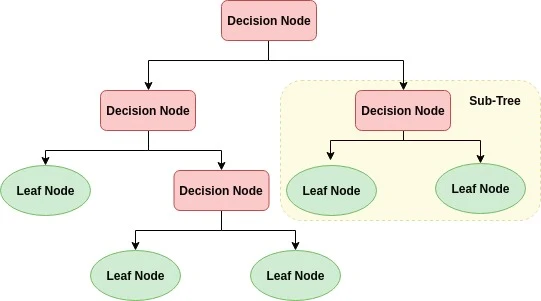

Arborele de decizii este un tip de algoritm white box - expus. Acesta împărtășește logica de luare a deciziilor interne, care nu este disponibilă în tipul de algoritmi black box, precum Rețea Neuronală. Timpul său de pregătire este mai rapid în comparație cu algoritmul rețelei neuronale. Complexitatea în timp a arborilor de decizie este o funcție a numărului de înregistrări și a numărului de atribute din datele date. Arborele decizional este o metodă fără distribuție sau non-parametrică, care nu depinde de presupunerile de distribuție a probabilității. Arborii de decizii pot trata datele de înaltă dimensiune cu o precizie bună.

> Problema cea mai mare este bias-ul sau sensitivitatea la schimbari in valorile atributelor.

### Cum funcționează algoritmul ?

- Selecteaza cel mai bun atribut folosind măsuri de selecție a atributelor (ASM) pentru a împărți înregistrările.
- Fa din acel atribut un nod de decizie și sparge setul de date în submultimi mai mici.
- Începe construirea arborilor prin repetarea acestui proces recursiv pentru fiecare copil până când una dintre urmatoarele se va potrivi:
    - Toate inregistrarile aparțin aceleiași valori de atribut.
    - Nu mai există alte atribute.
    - Nu mai există cazuri.
    
- se poate impune o adancime maxima pentru a evita supraadaptarea (overfitting). 

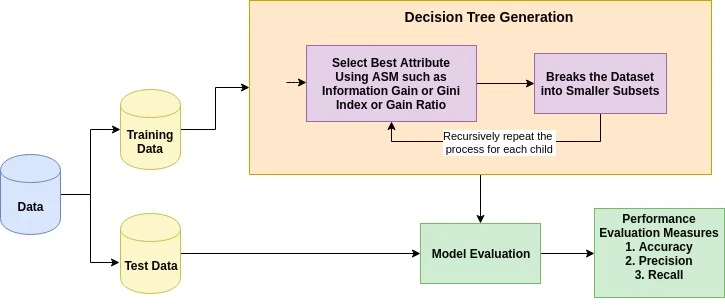

### Măsuri de selecție a atributelor (ASM)
Măsura de selecție a atributelor este o euristica pentru selectarea criteriului optim de partiționare. Este, de asemenea, cunoscut sub numele de reguli de divizare, deoarece ne ajută să determinăm punctele de întrerupere pentru tuple pe un nod dat. ASM oferă un rang fiecărei caracteristici (sau atribut) în explicarea setului de date dat. Cel mai bun atribut în funcție de scor va fi selectat ca atribut de divizare. În cazul unui atribut cu valoare continuă, punctele de împărțire pentru ramuri trebuie, de asemenea, definite. Cele mai populare măsuri de selecție sunt câștigul de informații (Information Gain), rata de câștig (Gain Ratio) și indicele Gini (Gini Index).

In exemplul de mai jos se studiaza in ce masura se poate determina predispozitia pentru diabet. Variabil tinta este coloana `label`. 

In [39]:
# Load libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation

In [40]:
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
# incarcare set date
pima = pd.read_csv("./date/pima-indians-diabetes.csv", header=0, names=col_names)

In [41]:
pima.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Selectarea atributelor informative (feature selection)
Aici, trebuie să împărțiți coloanele date în două tipuri de variabile dependente (sau variabile țintă) și variabilă independentă (sau variabile caracteristice sau covariatele).

In [42]:
#split dataset in features and target variable
feature_cols = ['pregnant', 'insulin', 'bmi', 'age','glucose','bp','pedigree']
X = pima[feature_cols] # Features
y = pima.label # Target variable

### Împărțirea datelor
Pentru a înțelege performanța modelului, împărțirea setului de date într-un set de antrenament și un set de teste este o strategie bună.

Să împărțim setul de date utilizând funcția train_test_split (). Trebuie să treceți 3 parametrii:
- X:covariatele
- y: variabila target/tinta 
- proportia setul de test in setul initial.


In [43]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.3, # 70% training and 30% test
                                                    random_state=1) # pentru reproductibilitate - in modul debug

Să creăm un model de arbore de decizie folosind Scikit-learning.

In [44]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

Evaluarea modelului creat

In [45]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.683982683982684


Să comparăm cu antrenare unui model kNN cu $k=11$.

In [46]:
from sklearn.neighbors import KNeighborsClassifier
knn_clf =KNeighborsClassifier(n_neighbors=11)

knn_clf = knn_clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = knn_clf.predict(X_test)
# Model Accuracy, how often is the classifier correct?
print("Accuracy kNN(k=11):",metrics.accuracy_score(y_test, y_pred))

Accuracy kNN(k=11): 0.7922077922077922


## Exercițiul 1 de laborator

Reprezentati grafic curba ROC si calculati AUC pentru acest clasificator - arbore de decizie.
> **Hint** - vedeti ce alte proprietati in afara de `metrics.accuracy_score` are obiectul `metrics` si cum se folosesc.

Ei bine, ați obținut o rată de clasificare de aprox 65-70%. Puteți îmbunătăți această precizie prin reglarea parametrilor din algoritm.

### Vizualizarea arborilor de decizie
Arborele se desenează direct cu funcția `sklearn.tree.plot_tree` (folosește matplotlib), fără instalări suplimentare.




In [47]:
import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin'

In [48]:
import matplotlib.pyplot as plt
from sklearn import tree

# desenarea arborelui direct cu scikit-learn + matplotlib (nu e nevoie de graphviz sau pydotplus)
plt.figure(figsize=(20, 10))
tree.plot_tree(clf, feature_names=feature_cols, class_names=['0', '1'], filled=True, rounded=True, fontsize=8)
plt.savefig('diabetes.png', dpi=150, bbox_inches='tight')
plt.show()

In [49]:
from sklearn import tree
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))
tree.plot_tree(
    clf,
    feature_names=feature_cols,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=12
)
plt.show()


# Parametrii
Cu ajutorul codului urmator puteti sa explorati efectul diferitelor atribute asupra structurii arborelui de decizie.

Parametrii sunt:
- criterion: Funcția de a măsura calitatea unei splitari. Criteriile acceptate sunt „gini” pentru Gini impurity index și „entropie” pentru Information Gain.

- splitter: Strategia folosită pentru a alege împărțirea la fiecare nod. Strategiile acceptate sunt „best” pentru a alege cea mai bună împărțire și „random” pentru a alege cea mai bună divizare aleatorie.

- max_depth: Adâncimea maximă a copacului. Dacă e setat pe `None`, atunci nodurile sunt extinse până când toate frunzele sunt pure sau până când toate frunzele conțin mai puțin de `min_samples_split` mostre.

- min_samples_split: Numărul minim de inregistrari in eșantioan necesar pentru a împărți un nod intern:

      - Dacă e un număr intreg, atunci acesta va fi considerat drept numărul minim de esantioane.

      - Dacă e un float (numar real), atunci min_samples_split este o proportie, iar plafonul (min_samples_split * n_samples) este numărul minim de probe pentru fiecare împărțire.

- min_samples_leaf: Numărul minim de observatii necesar să fie la un nod frunze. O ramificație la orice adâncime va fi luată în considerare numai dacă lasă cel puțin min_samples_leaf observatii în fiecare dintre ramurile din stânga și din dreapta. Aceasta poate avea efectul de a netezi modelul, în special în regresie.

In [50]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn import tree
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
from IPython.display import display                               
from ipywidgets import interactive
import sklearn.metrics as met
# # load dataset
# data = load_wine()
# # feature matrix
# X = data.data
# # target vector
# y = data.target
# class labels
labels = feature_cols

def plot_tree(crit, split, depth, min_split, min_leaf=0.2):
    estimator = DecisionTreeClassifier(random_state = 0 
          , criterion = crit
          , splitter = split
          , max_depth = depth
          , min_samples_split=min_split
          , min_samples_leaf=min_leaf)
    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)
    acc = met.accuracy_score(y_test, y_pred)
    print("Accuracy:",met.accuracy_score(y_test, y_pred))
    fig, ax = plt.subplots(figsize=(16, 8))
    tree.plot_tree(estimator, feature_names=labels, class_names=['0', '1'], filled=True, ax=ax)
    plt.show()
    return estimator,acc

inter=interactive(plot_tree 
   , crit = ["gini", "entropy"]
   , split = ["best", "random"]
   , depth=[1,2,3,4,5,6]
   , min_split=(0.1,1)
   , min_leaf=(0.1,0.5))
display(inter)

interactive(children=(Dropdown(description='crit', options=('gini', 'entropy'), value='gini'), Dropdown(descri…

Acest model toaletat (pruned) este mai puțin complex, explicabil și ușor de înțeles decât modelul precedent de model de arbore de decizie.

### Avantaje

- Arborii de decizie sunt ușor de interpretat și vizualizat.
- Poate captura cu ușurință modele neliniare.
- Este nevoie de mai puține preprocesări de date de la utilizator, de exemplu, nu este necesară normalizarea coloanelor.
- Poate fi utilizat pentru ingineria caracteristicilor, cum ar fi prezicerea valorilor lipsă, potrivite pentru selecția variabilă.
- Arborele decizional nu are presupuneri cu privire la distribuția din cauza naturii non-parametrice a algoritmului. (Sursă)

###  Dezavantaje

- Date sensibile la zgomot. Se pot potrivi cu date zgomotoase.
- Variația mică (sau variația) din date poate duce la arbori de decizie diferiti. 
- Arborii de decizie sunt afectati de un set de date cu clase dezechilibrate, de aceea este recomandat să echilibrezi setul de date înainte de a crea arborele de decizie

# METODE ENSEMBLE - bazate pe colecții de clasificatori

# Random Forest Classifier

Resură bună:
https://machinelearningmastery.com/random-forest-ensemble-in-python/

Cum functioneaza:
- Se selecteaza eșantioane aleatorii dintr-un set de date dat.
- Se construieste un arbore de decizie pentru fiecare eșantion și se obține un rezultat de predicție din fiecare arbore de decizie.
- Se acorda un vot pentru fiecare rezultat prevăzut.
- Se selecteaza rezultatul predicției cu cele mai multe voturi ca predicție finală.

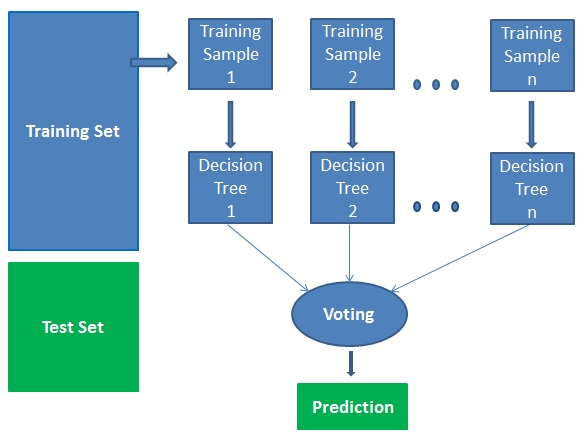

### Avantaje
- Pădurile aleatoare sunt considerate o metodă extrem de precisă și robustă datorită numărului de arbori de decizie care participă la proces.
- Nu suferă de problema de overfit sau bias. Motivul principal este că este nevoie de media tuturor predicțiilor, ceea ce anulează specificatea setului de date (bias/prejudecăți).
- Algoritmul poate fi utilizat atât în problemele de clasificare cât și în cele de regresie.
- Pădurile aleatoare pot gestiona, de asemenea, valorile lipsă. Există două modalități de gestionare a acestora: folosirea valorilor mediane pentru a înlocui variabilele continue și calcularea mediei ponderate de proximitate a valorilor lipsă.
- Puteți obține importanța relativă a caracteristicilor, ceea ce ajută la selectarea celor mai importante atribute pentru clasificator.

### Dezavantaje
- Pădurea aleatoare generează lent predicții, deoarece are mai mulți arbori de decizie. Ori de câte ori face o predicție, toți copacii din pădure trebuie să facă o predicție pentru același input dat și apoi să efectueze votul asupra acesteia. Tot acest proces necesită mult timp.
- Modelul este dificil de interpretat în comparație cu un arbore de decizie, unde puteți lua cu ușurință o decizie urmând calea din arbore.


### Parametrii

Prezentam in continuare cativa dintre parametrii implementarii din <a href="https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html" class="dc by ii ij ik il" target="_blank" rel="noopener nofollow">scikit-learn</a>

- n_estimators: Numărul de arbori din pădure.

- criterion: Funcția de a măsura calitatea unei splitari. Criteriile acceptate sunt „gini” pentru Gini impurity index și „entropie” pentru Information Gain.

- max_depth: Adâncimea maximă a arborilor. default=None: Dacă e setat pe `None`, atunci nodurile sunt extinse până când toate frunzele sunt pure sau până când toate frunzele conțin mai puțin de min_samples_split mostre.

- min_samples_split: (implicit = 2) Numărul minim de inregistrari necesar pentru a împărți un nod intern:

    - Dacă e un număr intreg, atunci acesta va fi considerat drept numărul minim de esantioane.

    - Dacă e un float (numar real), atunci min_samples_split este o proportie, iar plafonul (min_samples_split * n_samples) este numărul minim de probe pentru fiecare împărțire.



- min_samples_leaf: Numărul minim de inregistrari necesar să fie la un nod frunze. Un punct despărțit la orice adâncime va fi luat în considerare numai dacă lasă cel puțin min_samples_leaf probe de formare în fiecare dintre ramurile din stânga și din dreapta. Aceasta poate avea efectul de a netezi modelul, în special în regresie.

    - Dacă e int, atunci consideră min_samples_leaf drept numărul minim.

    - Dacă e float, atunci min_samples_leaf este o fracție, iar plafonul (min_samples_leaf * n_samples) este numărul minim de eșantioane pentru fiecare nod.

- min_weight_fraction_leaf: Fracția minimă ponderată din suma totală a greutăților (din toate eșantioanele de intrare) necesară pentru a fi la un nod frunze. Probele au o greutate egală atunci când nu este furnizat eșantion_weight.

- max_features: int, float, string sau None, opțional (implicit = "auto") Numărul de caracteristici care trebuie luate în considerare atunci când căutați cea mai bună împărțire:

    - Dacă int, atunci se iau în considerare max_features la fiecare împărțire.

    - Dacă float, atunci max_features este o proportie și sunt considerate caracteristici int (max_features * n_features) la fiecare împărțire.

    - Dacă „auto”, atunci max_features = sqrt (n_features).

    - Dacă „sqrt”, atunci max_features = sqrt (n_features) (la fel ca „auto”).

    - Dacă „log2”, max_features = log2 (n_features).

    - Dacă Niciuna, atunci max_features = n_features.

> Notă: căutarea unei împărțiri nu se oprește până când nu este găsită cel puțin o partiție validă a eșantioanelor nodului, chiar dacă este necesară inspecția eficientă a mai multor funcții max_features.


In [51]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3) # 70% training and 30% test

După divizare, veți antrena modelul pe setul de antrenament și veți face predicții pe setul de testare.


In [52]:

from sklearn.ensemble import RandomForestClassifier
import numpy

clf=RandomForestClassifier(
    n_estimators=200, 
    max_samples= 0.2,
#max_features =int(round(0.33*Xtrain.shape[1],0))
)

clf.fit(X_train,y_train)

y_pred=clf.predict(X_test)

In [53]:
#Import scikit-learn metrics module for accuracy calculation
import matplotlib as plt
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Matrice confuzie pe X_test (evaluarea):\n')
disp= met.ConfusionMatrixDisplay(met.confusion_matrix(y_test, y_pred))
disp.plot()
# plt.show()
metrics  = met.precision_recall_fscore_support (y_test,y_pred, average=None)
print('Accuracy', round(met.accuracy_score(y_test, y_pred),2))

# data frame dintr-un dictionar cu rezultatele din variabila metrics rearanjate 
pd.DataFrame([ 
   
    {'metric':'Precision',
   'class 0':round(metrics[0][0],2),
   'class 1':round(metrics[0][1],2)},
 {'metric':'Recall', 
   'class 0':round(metrics[1][0],2),
   'class 1':round(metrics[1][1],2)},
 {'metric':'F1-score', 
   'class 0':round(metrics[2][0],2),
   'class 1':round(metrics[2][1],2)}])
                                       

Matrice confuzie pe X_test (evaluarea):

Accuracy 0.73


,metric,class 0,class 1
0,Precision,0.74,0.69
1,Recall,0.89,0.43
2,F1-score,0.81,0.53


La fel ca si al arborii de decizie, si aici putem considera evaluarea clasificatorului cu curba ROC si AUC, dar si metricile Precision, Recall, F1 pentru un prag de 0.5 pentru scorul dat de random forest.

In [54]:
print(met.classification_report(y_true=y_test,y_pred = y_pred))

              precision    recall  f1-score   support

           0       0.74      0.89      0.81       148
           1       0.69      0.43      0.53        83

    accuracy                           0.73       231
   macro avg       0.71      0.66      0.67       231
weighted avg       0.72      0.73      0.71       231



# Exercițiu laborator 2

- curba ROC, AUC
- Recall, Precision, F1

## Exemplu de antrenare completa cu sklearn

### -  Am folosit Random Forest dar se poate folosi orice alt tip de model atat la clasificare cat si la regresie



In [55]:
X = pima[[c for c in pima if c!='label']]
y = pima['label']

In [56]:
pima.groupby('label').count()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age
label,,,,,,,,
0,500,500,500,500,500,500,500,500
1,268,268,268,268,268,268,268,268


In [57]:
# Import train_test_split function
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score as accuracy
from sklearn.model_selection import GridSearchCV

rfc=RandomForestClassifier(random_state=42)
    
param_grid = {
                'n_estimators': [10, 100, 200],
                'max_features': ['sqrt','log2'],
                'max_samples' : [0.2, 0.3, 0.4, 0.5 ,0.6],#,0.7, 0.8, 0.9] ,
                'criterion' :['gini', 'entropy']
             }
def antrenament_scikitlearn(X,y, model, params):
    
    
    CV_rfc = GridSearchCV(estimator=model, param_grid=params, cv= 5, n_jobs = -1,verbose = 1)
    CV_rfc.fit(X, y)
    
    return CV_rfc.best_params_, CV_rfc.best_estimator_

# n iteratii
n = 10
results = []
for i in range(10):
    
    print("Iteration {0} of {1}".format(i,n))
    # Split dataset into training set and test set
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3) # 70% training and 30% test
    
    params,model = antrenament_scikitlearn(X_train, y_train, rfc, param_grid)
    
    y_test_pred = model.predict(X_test)
    results.append({'acuratețe':accuracy(y_true = y_test, y_pred=y_test_pred),
                   'parametrii':params})
    

df_res = pd.DataFrame(results)
print("Average accuracy:", sum(df_res['acuratețe'])/df_res.shape[0])
df_res


Iteration 0 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 1 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 2 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 3 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 4 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


...

Iteration 7 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 8 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 9 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Average accuracy: 0.7532467532467532


,acuratețe,parametrii
0,0.761905,"{'criterion': 'gini', 'max_features': 'sqrt', ..."
1,0.783550,"{'criterion': 'entropy', 'max_features': 'log2..."
2,0.727273,"{'criterion': 'entropy', 'max_features': 'log2..."
3,0.748918,"{'criterion': 'entropy', 'max_features': 'sqrt..."
4,0.744589,"{'criterion': 'entropy', 'max_features': 'log2..."
5,0.748918,"{'criterion': 'gini', 'max_features': 'log2', ..."
6,0.727273,"{'criterion': 'entropy', 'max_features': 'sqrt..."
7,0.761905,"{'criterion': 'gini', 'max_features': 'log2', ..."
8,0.774892,"{'criterion': 'entropy', 'max_features': 'sqrt..."
9,0.753247,"{'criterion': 'entropy', 'max_features': 'log2..."


In [58]:
#Vedem ce parametrii au produs cel mai bun rezultat.

# ca sa vedem coloana netrunchiata:
pd.set_option('display.max_colwidth' , None)
df_res.sort_values(by = 'acuratețe',ascending = False)

,acuratețe,parametrii
1,0.783550,"{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 200}"
8,0.774892,"{'criterion': 'entropy', 'max_features': 'sqrt', 'max_samples': 0.4, 'n_estimators': 100}"
0,0.761905,"{'criterion': 'gini', 'max_features': 'sqrt', 'max_samples': 0.4, 'n_estimators': 200}"
7,0.761905,"{'criterion': 'gini', 'max_features': 'log2', 'max_samples': 0.6, 'n_estimators': 200}"
9,0.753247,"{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 200}"
3,0.748918,"{'criterion': 'entropy', 'max_features': 'sqrt', 'max_samples': 0.4, 'n_estimators': 100}"
5,0.748918,"{'criterion': 'gini', 'max_features': 'log2', 'max_samples': 0.5, 'n_estimators': 200}"
4,0.744589,"{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.4, 'n_estimators': 100}"
2,0.727273,"{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.6, 'n_estimators': 100}"
6,0.727273,"{'criterion': 'entropy', 'max_features': 'sqrt', 'max_samples': 0.5, 'n_estimators': 200}"


In [59]:
try:
    list_params = list(df_res.sort_values(by = 'acuratețe',ascending = False)['parametrii'].values)
except:
    list_params = [{'criterion': 'gini', 'max_features': 'sqrt', 'max_samples': 0.3, 'n_estimators': 100}
        ,{'criterion': 'entropy', 'max_features': 'sqrt', 'max_samples': 0.6, 'n_estimators': 200}
        ,{'criterion': 'gini', 'max_features': 'sqrt', 'max_samples': 0.5, 'n_estimators': 100}
        ,{'criterion': 'gini', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 100}
        ,{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 100}
        ,{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.5, 'n_estimators': 100}
        ,{'criterion': 'gini', 'max_features': 'sqrt', 'max_samples': 0.5, 'n_estimators': 200}
        ,{'criterion': 'gini', 'max_features': 'log2', 'max_samples': 0.6, 'n_estimators': 100}
        ,{'criterion': 'entropy', 'max_features': 'sqrt', 'max_samples': 0.5, 'n_estimators': 200}
        ,{'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 200}]
list_params[0]

{'criterion': 'entropy',
 'max_features': 'log2',
 'max_samples': 0.2,
 'n_estimators': 200}

## Validare cu cei mai buni parametrii

In [60]:
# import pentru spargere in vederea validarii incrucisate manuale
from sklearn.model_selection import KFold
# in caz ca nu a fost rulata celula mai sus, reimportam clasa de model
from sklearn.ensemble import RandomForestClassifier
# import metrici de evaluare model
from sklearn import metrics

# definirea numarul de submultimi egale cu care facem validarea incrucisata 
kf = KFold(n_splits=10)
kf.get_n_splits(X)


# lista in care culegem rezultatele
res_final=[]

# bucla seturi parametrii
params = list_params[0]
    
print("\n\nParametrii:", params)
# definirea modelului cu cei mai buni parametrii
rfc=RandomForestClassifier(random_state=42,
                           criterion = params['criterion'], 
                           max_features = params['max_features'], 
                           max_samples = params['max_samples'], 
                           n_estimators = params['n_estimators'])


# bucla pythonica peste spargere
for i, (train_index, test_index) in enumerate(kf.split(X)):


    print(f"Test pe submultimea {i}:")
    # definirea seturilor de antrenament si test
    X_train,y_train,X_test,y_test = X.iloc[train_index,:],y.iloc[train_index],X.iloc[test_index,:],y.iloc[test_index]

    # pas de antrenare
    rfc.fit(X_train,y_train)

    # pas de predictie pe datele nefolosite in anternare
    y_test_pred = rfc.predict(X_test)

    # adaugarea rezultatelor sub forma de dictionare pentru a putea transforma usor in dataframe la sfarsit
    res_final.append(
        { 
            'parametrii': '|'.join([ k+':'+str(params[k]) for k in params.keys()]),
            'matrice_confuzie': metrics.confusion_matrix(y_pred = y_test_pred,y_true = y_test),
        'acuratete':metrics.accuracy_score(y_pred = y_test_pred,y_true = y_test),
        'precision':metrics.precision_score(y_pred = y_test_pred,y_true = y_test),
        'recall':metrics.recall_score(y_pred = y_test_pred,y_true = y_test),
        'f1':metrics.f1_score(y_pred = y_test_pred,y_true = y_test)}
)

# transformarea listei de dictionare in dataframe pentru vizualizare
pd.DataFrame(res_final).groupby('parametrii', as_index = False)['acuratete'].mean()



Parametrii: {'criterion': 'entropy', 'max_features': 'log2', 'max_samples': 0.2, 'n_estimators': 200}
Test pe submultimea 0:
Test pe submultimea 1:


Test pe submultimea 2:
Test pe submultimea 3:
Test pe submultimea 4:


Test pe submultimea 5:
Test pe submultimea 6:


Test pe submultimea 7:
Test pe submultimea 8:
Test pe submultimea 9:


,parametrii,acuratete
0,criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200,0.776008


In [61]:
res_final

[{'parametrii': 'criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200',
  'matrice_confuzie': array([[36,  9],
         [12, 20]]),
  'acuratete': 0.7272727272727273,
  'precision': 0.6896551724137931,
  'recall': 0.625,
  'f1': 0.6557377049180327},
 {'parametrii': 'criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200',
  'matrice_confuzie': array([[51,  4],
         [ 9, 13]]),
  'acuratete': 0.8311688311688312,
  'precision': 0.7647058823529411,
  'recall': 0.5909090909090909,
  'f1': 0.6666666666666666},
 {'parametrii': 'criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200',
  'matrice_confuzie': array([[37,  6],
         [15, 19]]),
  'acuratete': 0.7272727272727273,
  'precision': 0.76,
  'recall': 0.5588235294117647,
  'f1': 0.6440677966101694},
 {'parametrii': 'criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200',
  'matrice_confuzie': array([[37, 10],
         [14, 16]]),
  'acuratete': 0.6883116883116883,
  'prec

In [62]:
# transformarea listei de dictionare in dataframe pentru vizualizare

pd.set_option('display.max_colwidth',None)

df_res_final = pd.DataFrame(res_final)
# df_res_final['params_string'] = df_res_final.parametrii.apply(
#     lambda x: '|'.join([str(key)+'='+str(x[key]) for key in x.keys()])
# )
df_res_final.groupby('parametrii', as_index = False)['acuratete'].mean().sort_values(by = 'acuratete',
                                                                                       ascending = False)

,parametrii,acuratete
0,criterion:entropy|max_features:log2|max_samples:0.2|n_estimators:200,0.776008


## XGBOOST - Gradient Boosting

## Parametrii de explorat
### Explorați numărul de arbori - n_estimators
Un hiperparametru important pentru algoritmul de ansamblu XGBoost este numărul de arbori de decizie utilizați în ansamblu.

Amintiți-vă că arborii de decizie sunt adăugați la model secvențial într-un efort de a corecta și îmbunătăți predicțiile făcute de arborii anteriori. Ca atare, mai mulți copaci este adesea mai bine.

Numărul de arbori poate fi setat prin argumentul „n_estimators” și este implicit la 100.

Exemplul de mai jos explorează efectul numărului de copaci cu valori între 10 și 5.000.

### Explorați adâncimea arborilor - max_depth
Varierea adâncimii fiecărui copac adăugat ansamblului este un alt hiperparametru important pentru creșterea gradientului.

Adâncimea arborelui controlează cât de specializat este fiecare arbore față de setul de date de antrenament: cât de general sau supraadaptat ar putea fi. Se preferă arborii care nu sunt prea superficiali și generali (cum ar fi AdaBoost) și nici prea adânci și specializați (cum ar fi agregarea bootstrap).

În general, creșterea gradului funcționează bine cu copacii care au o adâncime modestă, găsind un echilibru între îndemânare și generalitate.

Adâncimea arborelui este controlată prin argumentul „max_depth” și este implicit la 6.

Exemplul de mai jos explorează adâncimile copacilor între 1 și 10 și efectul asupra performanței modelului.

### Explorați rata de învățare - eta
Rata de învățare controlează valoarea contribuției pe care fiecare model o are asupra predicției ansamblului.

Ratele mai mici pot necesita mai mulți arbori de decizie în ansamblu.

Rata de învățare poate fi controlată prin argumentul „eta” și este implicit la 0,3.

Exemplul de mai jos explorează rata de învățare și compară efectul valorilor între 0,0001 și 1,0.

### Explorați mărimea eșantionului - subsample
Numărul de mostre utilizate pentru a se potrivi fiecărui copac poate fi variat. Aceasta înseamnă că fiecare arbore se potrivește într-un subset selectat aleatoriu al setului de date de antrenament.

Utilizarea mai puține mostre introduce mai multă variație pentru fiecare arbore, deși poate îmbunătăți performanța generală a modelului.

Numărul de mostre utilizate pentru a se potrivi fiecărui arbore este specificat de argumentul „subeșantion” și poate fi setat la o fracțiune din dimensiunea setului de date de antrenament. În mod implicit, este setat la 1.0 pentru a utiliza întregul set de date de antrenament.

Exemplul de mai jos demonstrează efectul mărimii eșantionului asupra performanței modelului, cu rapoarte variind de la 10% la 100% în trepte de 10%.

### Explorați numărul de caracteristici - colsample_bytree
Numărul de caracteristici utilizate pentru a se potrivi fiecărui arbore de decizie poate fi variat.

La fel ca schimbarea numărului de eșantioane, modificarea numărului de caracteristici introduce variații suplimentare în model, ceea ce poate îmbunătăți performanța, deși ar putea necesita o creștere a numărului de arbori.

Numărul de caracteristici utilizate de fiecare arbore este luat ca un eșantion aleatoriu și este specificat de argumentul „colsample_bytree” și este implicit pentru toate caracteristicile din setul de date de antrenament, de ex. 100 la sută sau o valoare de 1,0. De asemenea, puteți eșantiona coloane pentru fiecare împărțire, iar acest lucru este controlat de argumentul „colsample_bylevel”, dar nu ne vom uita la acest hiperparametru aici.

Exemplul de mai jos explorează efectul numărului de caracteristici asupra performanței modelului, cu rapoarte variind de la 10% la 100% în trepte de 10%.

# Implementarea din sklearn

In [63]:
from sklearn.ensemble import GradientBoostingClassifier

In [64]:
model = GradientBoostingClassifier()
param_grid = {
                'n_estimators': [10, 100, 200],
                'max_features': ['sqrt'],
                'subsample' : [0.2, 0.3, 0.4, 0.5 ,0.6],#,0.7, 0.8, 0.9] ,
                'learning_rate' :[0.001, 0.03, 0.5, 1]
             }
def antrenament_scikitlearn(X,y, model, params):
    
    
    CV_rfc = GridSearchCV(estimator=model, param_grid=params, cv= 5, n_jobs = -1,verbose = 1)
    CV_rfc.fit(X, y)
    
    return CV_rfc.best_params_, CV_rfc.best_estimator_

# n iteratii
n = 10
results = []
for i in range(10):
    
    print("Iteration {0} of {1}".format(i,n))
    # Split dataset into training set and test set
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3) # 70% training and 30% test
    
    params,model = antrenament_scikitlearn(X_train, y_train, model, param_grid)
    
    y_test_pred = model.predict(X_test)
    results.append({'acuratețe':accuracy(y_true = y_test, y_pred=y_test_pred),
                   'parametrii':params})
    

df_res = pd.DataFrame(results)
print("Average accuracy:", sum(df_res['acuratețe'])/df_res.shape[0])
df_res

Iteration 0 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 1 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 2 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 3 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 4 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


...

Iteration 7 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 8 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Iteration 9 of 10
Fitting 5 folds for each of 60 candidates, totalling 300 fits


Average accuracy: 0.7519480519480519


,acuratețe,parametrii
0,0.735931,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.3}"
1,0.722944,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.4}"
2,0.740260,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 200, 'subsample': 0.4}"
3,0.744589,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.4}"
4,0.727273,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.5}"
5,0.744589,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.6}"
6,0.766234,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.6}"
7,0.774892,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 200, 'subsample': 0.4}"
8,0.792208,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.5}"
9,0.770563,"{'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.3}"


In [65]:
list_params = list(df_res.sort_values(by = 'acuratețe',ascending = False)['parametrii'].values)

# definirea numarul de submultimi egale cu care facem validarea incrucisata 
kf = KFold(n_splits=10)
kf.get_n_splits(X)


# lista in care culegem rezultatele
res_final=[]

# bucla seturi parametrii
params = list_params[0]
    
print("\n\nParametrii:", params)
# definirea modelului cu cei mai buni parametrii
gbc=GradientBoostingClassifier(
                            
                           max_features = params['max_features'], 
                           subsample = params['subsample'], 
                           n_estimators = params['n_estimators'],
    learning_rate = params['learning_rate']
)


# bucla pythonica peste spargere
for i, (train_index, test_index) in enumerate(kf.split(X)):


    print(f"Test pe submultimea {i}:")
    # definirea seturilor de antrenament si test
    X_train,y_train,X_test,y_test = X.iloc[train_index,:],y.iloc[train_index],X.iloc[test_index,:],y.iloc[test_index]

    # pas de antrenare
    gbc.fit(X_train,y_train)

    # pas de predictie pe datele nefolosite in anternare
    y_test_pred = gbc.predict(X_test)

    # adaugarea rezultatelor sub forma de dictionare pentru a putea transforma usor in dataframe la sfarsit
    res_final.append(
        { 
            'parametrii': '|'.join([ k+':'+str(params[k]) for k in params.keys()]),
            'matrice_confuzie': metrics.confusion_matrix(y_pred = y_test_pred,y_true = y_test),
        'acuratete':metrics.accuracy_score(y_pred = y_test_pred,y_true = y_test),
        'precision':metrics.precision_score(y_pred = y_test_pred,y_true = y_test),
        'recall':metrics.recall_score(y_pred = y_test_pred,y_true = y_test),
        'f1':metrics.f1_score(y_pred = y_test_pred,y_true = y_test)}
)

# transformarea listei de dictionare in dataframe pentru vizualizare
pd.DataFrame(res_final).groupby('parametrii', as_index = False)['acuratete'].mean()



Parametrii: {'learning_rate': 0.03, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.5}
Test pe submultimea 0:
Test pe submultimea 1:
Test pe submultimea 2:
Test pe submultimea 3:
Test pe submultimea 4:
Test pe submultimea 5:


Test pe submultimea 6:
Test pe submultimea 7:
Test pe submultimea 8:
Test pe submultimea 9:


,parametrii,acuratete
0,learning_rate:0.03|max_features:sqrt|n_estimators:100|subsample:0.5,0.762987


# O alta implementare, din afara sklearn

Aceasta este implementare dedicata, merita incercata - eu doar pe aceasta o folosesc in practica. Se antreneaza insa mai greu

In [66]:
# evaluate xgboost ensemble for regression
from numpy import mean
from numpy import std

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedKFold
from xgboost import XGBClassifier

import gc
gc.collect()

1272

> **Atenție:** celula de mai jos încearcă multe combinații și rulează aproximativ 10 minute.

In [67]:
# exemple de gridsearch liniar
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

def get_model_params(param_to_test):
    
    if param_to_test == 'n_estimators':
        trees = [10, 50, 100, 500]
        return trees
            
    elif param_to_test == 'max_depth': 
        return [ i for i in range(1,11)]
        
    elif param_to_test == 'eta_learning_rate':

        rates = [ 0.001, 0.01, 0.1, 1.0]
        return rates
    
    elif param_to_test == 'subsample':
    
        return [t/10 for t in range(1,11)]
            
            
    elif param_to_test == 'colsample_bytree':
        return [t/10 for t in range(1,11)]
            
# evaluate a give model using cross-validation
def evaluate_model(model,X_eval,y_eval):
    cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=1)
    scores = cross_val_score(model, X_eval, y_eval, scoring='neg_log_loss', cv=cv, n_jobs=5)
    return scores

res_list = []
n_estimators = get_model_params('n_estimators')
max_depths = get_model_params('max_depth')
eta_learning_rates = get_model_params('eta_learning_rate')
subsamples = get_model_params('subsample')
colsample_bytrees = get_model_params('colsample_bytree')


for n_estimators_s in n_estimators:
    for max_depth in max_depths:
        for eta_learning_rate in eta_learning_rates:
            for subsample in subsamples:
                for colsample_bytree in colsample_bytrees:
                    
                    # get the models to evaluate

                    model = XGBClassifier(
                        n_estimators = n_estimators_s,
                        max_depth = max_depth,
                        eta = eta_learning_rate,
                        subsample = subsample,
                        colsample_bytree = colsample_bytree
                    )
                    
                    dict_params = {
                         'n_estimators_s': n_estimators_s,
                       'max_depth': max_depth,
                       'eta_learning_rate': eta_learning_rate,
                        'subsample': subsample,
                        'colsample_bytree': colsample_bytree
                    }
                    print('Processing  for :')
                   
                    #scores = evaluate_model(model, X_train,y_train)

                    model.fit(X_train, y_train)

                    #names.append(name)

                    yhat = model.predict(X_test)
                    yhat_train = model.predict(X_train)
                    #print('Prediction: %d' % yhat)
                    res_dict = {}
                    res_dict['params'] = dict_params
                    res_dict['confusion_matrix'] = met.confusion_matrix(y_test, yhat)
                    res_dict['metrics'] =  met.precision_recall_fscore_support (y_test,yhat)
                    res_list.append(res_dict)
                    print(res_dict)
        #results.append(abs(y_test-yhat.reshape(y_test.shape[0])))
        # plot model performance for comparison

Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.1, 'colsample_bytree': 0.1}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.1, 'colsample_bytree': 0.2}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.1, 'colsample_bytree': 0.3}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_

{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.2, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.2, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.2, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.

{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.5, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.5, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.5, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.

{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.8, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.8, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.001, 'subsample': 0.8, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.

{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.01, 'subsample': 0.1, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.01, 'subsample': 0.1, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.01, 'subsample': 0.1, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[46,  0],
       [30,  0]]), 'metrics': (array([0.60526316, 0.        ]), array([1., 0.]), array([0.75409836, 0.        ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 10, 'max_depth': 1, 'eta_learning_rate': 0.01,

...

{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 0.6}, 'confusion_matrix': array([[40,  6],
       [12, 18]]), 'metrics': (array([0.76923077, 0.75      ]), array([0.86956522, 0.6       ]), array([0.81632653, 0.66666667]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 0.7}, 'confusion_matrix': array([[38,  8],
       [12, 18]]), 'metrics': (array([0.76      , 0.69230769]), array([0.82608696, 0.6       ]), array([0.79166667, 0.64285714]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[37,  9],
       [14, 16]]), 'metrics': (array([0.7254902, 0.64     ]), array([0.80434783, 0.53333333]), array([0.7628866 , 0.58181818]), array([46, 30]))}
Processing  for :


{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[37,  9],
       [13, 17]]), 'metrics': (array([0.74      , 0.65384615]), array([0.80434783, 0.56666667]), array([0.77083333, 0.60714286]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[37,  9],
       [ 9, 21]]), 'metrics': (array([0.80434783, 0.7       ]), array([0.80434783, 0.7       ]), array([0.80434783, 0.7       ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.1}, 'confusion_matrix': array([[36, 10],
       [18, 12]]), 'metrics': (array([0.66666667, 0.54545455]), array([0.7826087, 0.4      ]), array([0.72      , 0.46153846]), array([46, 30]))}
Processing  for :


{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.2}, 'confusion_matrix': array([[36, 10],
       [18, 12]]), 'metrics': (array([0.66666667, 0.54545455]), array([0.7826087, 0.4      ]), array([0.72      , 0.46153846]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.3}, 'confusion_matrix': array([[36, 10],
       [11, 19]]), 'metrics': (array([0.76595745, 0.65517241]), array([0.7826087 , 0.63333333]), array([0.77419355, 0.6440678 ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.4}, 'confusion_matrix': array([[43,  3],
       [13, 17]]), 'metrics': (array([0.76785714, 0.85      ]), array([0.93478261, 0.56666667]), array([0.84313725, 0.68      ]), array([46, 30]))}
Processing  for :


{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.5}, 'confusion_matrix': array([[40,  6],
       [13, 17]]), 'metrics': (array([0.75471698, 0.73913043]), array([0.86956522, 0.56666667]), array([0.80808081, 0.64150943]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.6}, 'confusion_matrix': array([[40,  6],
       [13, 17]]), 'metrics': (array([0.75471698, 0.73913043]), array([0.86956522, 0.56666667]), array([0.80808081, 0.64150943]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.7}, 'confusion_matrix': array([[37,  9],
       [10, 20]]), 'metrics': (array([0.78723404, 0.68965517]), array([0.80434783, 0.66666667]), array([0.79569892, 0.6779661 ]), array([46, 30]))}
Processing  for :


{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.8}, 'confusion_matrix': array([[37,  9],
       [10, 20]]), 'metrics': (array([0.78723404, 0.68965517]), array([0.80434783, 0.66666667]), array([0.79569892, 0.6779661 ]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 0.9}, 'confusion_matrix': array([[36, 10],
       [12, 18]]), 'metrics': (array([0.75      , 0.64285714]), array([0.7826087, 0.6      ]), array([0.76595745, 0.62068966]), array([46, 30]))}
Processing  for :
{'params': {'n_estimators_s': 500, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 1.0, 'colsample_bytree': 1.0}, 'confusion_matrix': array([[38,  8],
       [12, 18]]), 'metrics': (array([0.76      , 0.69230769]), array([0.82608696, 0.6       ]), array([0.79166667, 0.64285714]), array([46, 30]))}


In [68]:
df_res = pd.DataFrame(res_list)
df_res['accuracy'] = df_res.confusion_matrix.apply(lambda x : (x[0][0]+x[1][1])/sum(sum(x)))

df_res.sort_values(by ='accuracy',ascending = False)

,params,confusion_matrix,metrics,accuracy
5426,"{'n_estimators_s': 50, 'max_depth': 4, 'eta_learning_rate': 0.1, 'subsample': 0.3, 'colsample_bytree': 0.7}","[[42, 4], [7, 23]]","([0.8571428571428571, 0.8518518518518519], [0.9130434782608695, 0.7666666666666667], [0.8842105263157894, 0.8070175438596491], [46, 30])",0.855263
1182,"{'n_estimators_s': 10, 'max_depth': 3, 'eta_learning_rate': 1.0, 'subsample': 0.9, 'colsample_bytree': 0.3}","[[43, 3], [8, 22]]","([0.8431372549019608, 0.88], [0.9347826086956522, 0.7333333333333333], [0.8865979381443299, 0.8], [46, 30])",0.855263
4344,"{'n_estimators_s': 50, 'max_depth': 1, 'eta_learning_rate': 1.0, 'subsample': 0.5, 'colsample_bytree': 0.5}","[[41, 5], [7, 23]]","([0.8541666666666666, 0.8214285714285714], [0.8913043478260869, 0.7666666666666667], [0.8723404255319149, 0.7931034482758621], [46, 30])",0.842105
9016,"{'n_estimators_s': 100, 'max_depth': 3, 'eta_learning_rate': 0.1, 'subsample': 0.2, 'colsample_bytree': 0.7}","[[42, 4], [8, 22]]","([0.84, 0.8461538461538461], [0.9130434782608695, 0.7333333333333333], [0.875, 0.7857142857142857], [46, 30])",0.842105
10607,"{'n_estimators_s': 100, 'max_depth': 7, 'eta_learning_rate': 0.1, 'subsample': 0.1, 'colsample_bytree': 0.8}","[[41, 5], [7, 23]]","([0.8541666666666666, 0.8214285714285714], [0.8913043478260869, 0.7666666666666667], [0.8723404255319149, 0.7931034482758621], [46, 30])",0.842105
...,...,...,...,...
7925,"{'n_estimators_s': 50, 'max_depth': 10, 'eta_learning_rate': 1.0, 'subsample': 0.3, 'colsample_bytree': 0.6}","[[29, 17], [18, 12]]","([0.6170212765957447, 0.41379310344827586], [0.6304347826086957, 0.4], [0.6236559139784946, 0.4067796610169492], [46, 30])",0.539474
6709,"{'n_estimators_s': 50, 'max_depth': 7, 'eta_learning_rate': 1.0, 'subsample': 0.1, 'colsample_bytree': 1.0}","[[33, 13], [22, 8]]","([0.6, 0.38095238095238093], [0.717391304347826, 0.26666666666666666], [0.6534653465346535, 0.3137254901960784], [46, 30])",0.539474
5909,"{'n_estimators_s': 50, 'max_depth': 5, 'eta_learning_rate': 1.0, 'subsample': 0.1, 'colsample_bytree': 1.0}","[[33, 13], [22, 8]]","([0.6, 0.38095238095238093], [0.717391304347826, 0.26666666666666666], [0.6534653465346535, 0.3137254901960784], [46, 30])",0.539474
6309,"{'n_estimators_s': 50, 'max_depth': 6, 'eta_learning_rate': 1.0, 'subsample': 0.1, 'colsample_bytree': 1.0}","[[33, 13], [22, 8]]","([0.6, 0.38095238095238093], [0.717391304347826, 0.26666666666666666], [0.6534653465346535, 0.3137254901960784], [46, 30])",0.539474


# Cei mai buni parametrii

In [69]:
# exemple de gridsearch liniar, fara a testa combinatii, ci doar cate unul pe rand
import warnings
import matplotlib.pylab as plt
from sklearn import metrics
warnings.filterwarnings("ignore", category=FutureWarning)

best_params = {
    'n_estimators_s': 50,
    'max_depth': 5, 
    'eta_learning_rate': 0.001, 
    'subsample': 0.2, 
    'colsample_bytree': 1.0}
model = XGBClassifier(
n_estimators =50,
max_depth = 5,
eta = 0.001,
subsample = 0.2,
colsample_bytree = 1
)


# definirea numarul de submultimi egale cu care facem validarea incrucisata 
kf = KFold(n_splits=10)
kf.get_n_splits(X)


# lista in care culegem rezultatele
res_final=[]

# bucla pythonica peste spargere
for i, (train_index, test_index) in enumerate(kf.split(X)):


    print(f"Test pe submultimea {i}:")
    # definirea seturilor de antrenament si test
    X_train,y_train,X_test,y_test = X.iloc[train_index,:],y.iloc[train_index],X.iloc[test_index,:],y.iloc[test_index]
    model.fit(X_train, y_train)
    yhat = model.predict(X_test)

#     print('Matrice confuzie pe X_test (evaluarea):\n')
#     disp= metrics.ConfusionMatrixDisplay(metrics.confusion_matrix(y_test, yhat))
#     disp.plot()
#     plt.show()
    test_metrics  = metrics.precision_recall_fscore_support (y_test, yhat, average=None)
    print('Accuracy', round(metrics.accuracy_score(y_test, yhat),2))
    res_final.append(

        {
            'Cofusion matrix':metrics.confusion_matrix(y_test, yhat),
            'Accuracy': round(metrics.accuracy_score(y_test, yhat),2),
            'Precision class 0':round(test_metrics[0][0],2),
            'Precision class 1':round(test_metrics[0][1],2),
            'Recall class 0':round(test_metrics[1][0],2),
            'Recal class 1':round(test_metrics[1][1],2),
            'F1-score class 0':round(test_metrics[2][0],2),
           'F1-score class 1':round(test_metrics[2][1],2)
        }

        )
pd.DataFrame(res_final).sort_values(by = 'Accuracy', ascending = False)                                      

Test pe submultimea 0:
Accuracy 0.58
Test pe submultimea 1:
Accuracy 0.71
Test pe submultimea 2:
Accuracy 0.56
Test pe submultimea 3:
Accuracy 0.61
Test pe submultimea 4:
Accuracy 0.65
Test pe submultimea 5:
Accuracy 0.61
Test pe submultimea 6:
Accuracy 0.82
Test pe submultimea 7:
Accuracy 0.68
Test pe submultimea 8:
Accuracy 0.68
Test pe submultimea 9:
Accuracy 0.61


,Cofusion matrix,Accuracy,Precision class 0,Precision class 1,Recall class 0,Recal class 1,F1-score class 0,F1-score class 1
6,"[[63, 0], [14, 0]]",0.82,0.82,0.0,1.0,0.0,0.90,0.0
1,"[[55, 0], [22, 0]]",0.71,0.71,0.0,1.0,0.0,0.83,0.0
8,"[[52, 0], [24, 0]]",0.68,0.68,0.0,1.0,0.0,0.81,0.0
7,"[[52, 0], [25, 0]]",0.68,0.68,0.0,1.0,0.0,0.81,0.0
4,"[[50, 0], [27, 0]]",0.65,0.65,0.0,1.0,0.0,0.79,0.0
3,"[[47, 0], [30, 0]]",0.61,0.61,0.0,1.0,0.0,0.76,0.0
9,"[[46, 0], [30, 0]]",0.61,0.61,0.0,1.0,0.0,0.75,0.0
5,"[[47, 0], [30, 0]]",0.61,0.61,0.0,1.0,0.0,0.76,0.0
0,"[[45, 0], [32, 0]]",0.58,0.58,0.0,1.0,0.0,0.74,0.0
2,"[[43, 0], [34, 0]]",0.56,0.56,0.0,1.0,0.0,0.72,0.0


In [70]:
print('acuratete medie:',pd.DataFrame(res_final).Accuracy.mean())

acuratete medie: 0.651
